<a href="https://colab.research.google.com/github/teku29/hotel-booking-analysis/blob/main/Hotel_Booking_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("hotel_bookings.csv")
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


**# 1. Data Cleaning**


In [30]:
# 1. Remove duplicates
df = df.drop_duplicates()

# 2. Drop 'company' (94% missing)
df = df.drop(columns=["company"])

# 3. Fill missing values
df["agent"] = df["agent"].fillna(0).astype(int)
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")

# 4. Fix data types
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

# 5. Remove invalid rows (zero guests, negative ADR)
df = df[(df["adults"] + df["children"] + df["babies"]) > 0]
df = df[df["adr"] >= 0]

print(df.shape)
print(df.isna().sum().sum())

(87229, 31)
0


Removed 31,994 duplicate rows, dropped `company` (94% missing), filled missing `agent`, `children` and `country`, converted the date column, and removed 166 zero-guest rows and 1 negative ADR row. Final dataset: 87,229 rows, 0 missing values.

 **#2. Descriptive Statistics**

In [31]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
is_canceled,87229.0,0.275241,0.0,0.0,0.0,1.0,1.0,0.446638
lead_time,87229.0,79.9697,0.0,11.0,49.0,125.0,737.0,86.058295
arrival_date_year,87229.0,2016.210343,2015.0,2016.0,2016.0,2017.0,2017.0,0.686063
arrival_date_week_number,87229.0,26.835284,1.0,16.0,27.0,37.0,53.0,13.669175
arrival_date_day_of_month,87229.0,15.815956,1.0,8.0,16.0,23.0,31.0,8.83552
stays_in_weekend_nights,87229.0,1.004574,0.0,0.0,1.0,2.0,19.0,1.027364
stays_in_week_nights,87229.0,2.623887,0.0,1.0,2.0,4.0,50.0,2.03981
adults,87229.0,1.879364,0.0,2.0,2.0,2.0,55.0,0.621727
children,87229.0,0.138899,0.0,0.0,0.0,0.0,10.0,0.456267
babies,87229.0,0.010845,0.0,0.0,0.0,0.0,10.0,0.113704


In [32]:
df.describe(include="object").T

,count,unique,top,freq
hotel,87229,2,City Hotel,53274
arrival_date_month,87229,12,August,11242
meal,87229,5,BB,67906
country,87229,178,PRT,27355
market_segment,87229,8,Online TA,51553
distribution_channel,87229,5,TA/TO,69028
reserved_room_type,87229,9,A,56435
assigned_room_type,87229,11,A,46283
deposit_type,87229,3,No Deposit,86084
customer_type,87229,4,Transient,71862


In [33]:
df["is_canceled"].value_counts(normalize=True) * 100

,proportion
is_canceled,
0,72.475897
1,27.524103


About 27.5% of all bookings are cancelled, so roughly 1 in 4 bookings does not result in a stay

**# 3. Data Visualization**

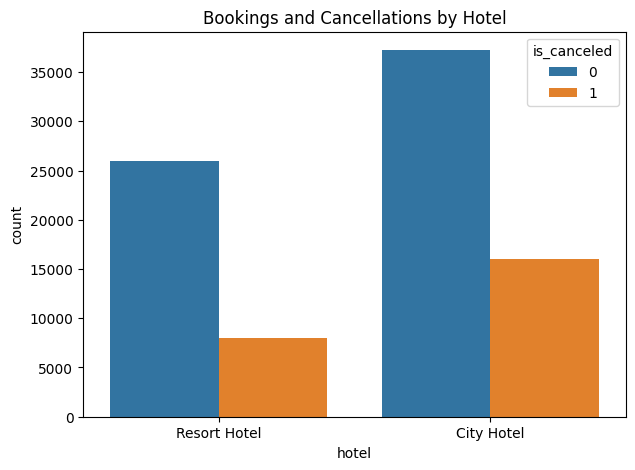

In [34]:
plt.figure(figsize=(7,5))
sns.countplot(x="hotel", data=df, hue="is_canceled")
plt.title("Bookings and Cancellations by Hotel")
plt.show()

City Hotel gets more bookings than Resort Hotel (about 53,000 vs 34,000) and also has a higher cancellation rate (about 30% vs 23%)

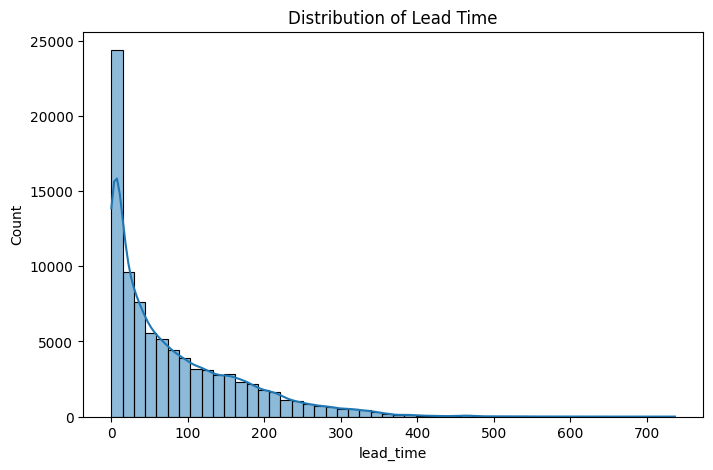

In [35]:
plt.figure(figsize=(8,5))
sns.histplot(df["lead_time"], bins=50, kde=True)
plt.title("Distribution of Lead Time")
plt.show()

Most guests book close to arrival, with about 69% booking within 100 days. The median lead time is 49 days, and a small share of bookings (about 3%) are made more than 300 days ahead

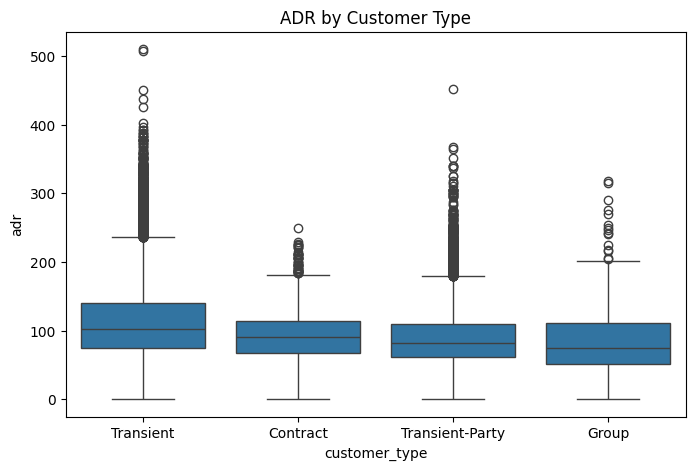

In [36]:
plt.figure(figsize=(8,5))
sns.boxplot(x="customer_type", y="adr", data=df[df["adr"] < 1000])
plt.title("ADR by Customer Type")
plt.show()

Transient customers pay the highest median ADR (about 102), while Group customers pay the lowest (about 75)

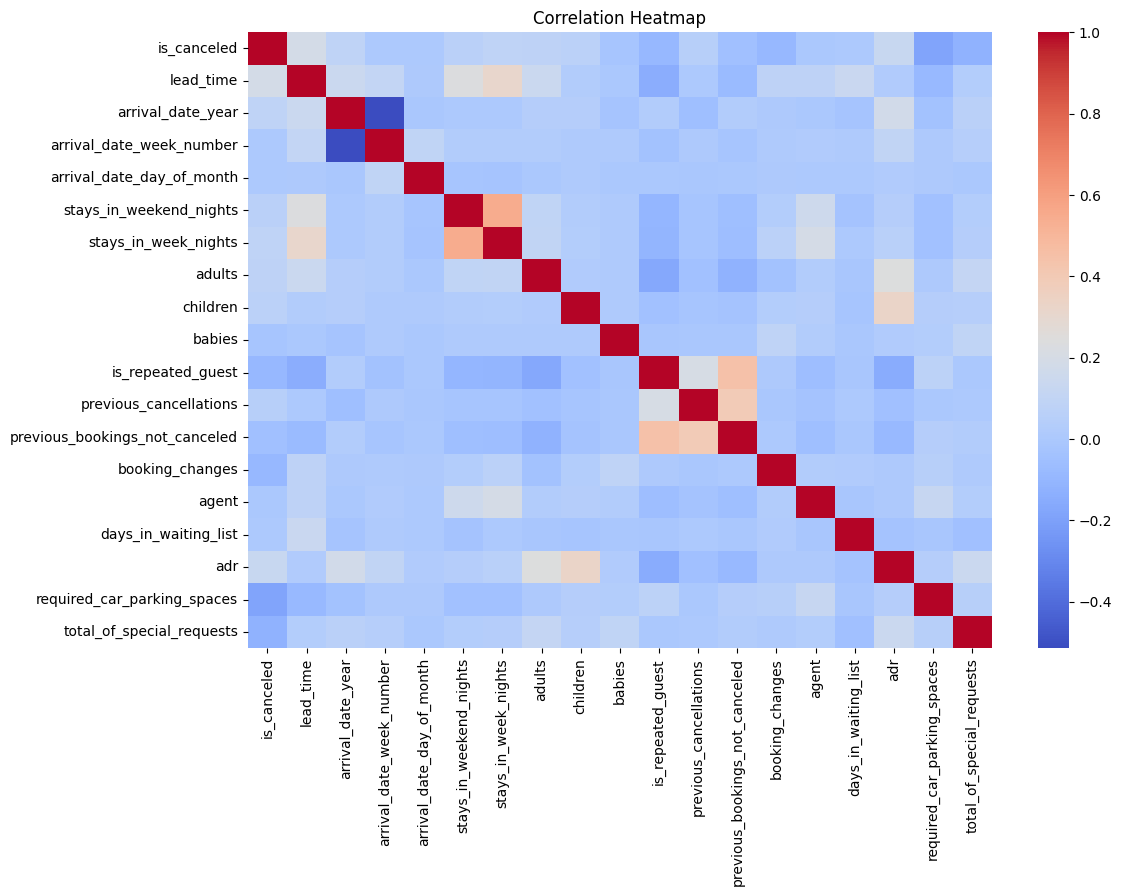

In [37]:
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()

Lead time has the strongest positive link with cancellation (about 0.18), so longer lead times mean slightly higher cancellation risk. Parking spaces (-0.18) and special requests (-0.12) have the strongest negative links, so guests who ask for these are less likely to cancel.

**# 4. Time Series Analysis**

In [38]:
months = ["January","February","March","April","May","June",
          "July","August","September","October","November","December"]

df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str)
)

In [39]:
monthly = df.groupby(df["arrival_date"].dt.to_period("M")).size().reset_index(name="bookings")
monthly["arrival_date"] = monthly["arrival_date"].astype(str)

fig = px.line(monthly, x="arrival_date", y="bookings", title="Monthly Bookings Over Time")
fig.show()

Q2. Which month has the highest number of bookings?

arrival_date_month
January       4685
February      6083
March         7488
April         7900
May           8344
June          7756
July         10043
August       11242
September     6682
October       6921
November      4973
December      5112
Name: count, dtype: int64
Highest: August


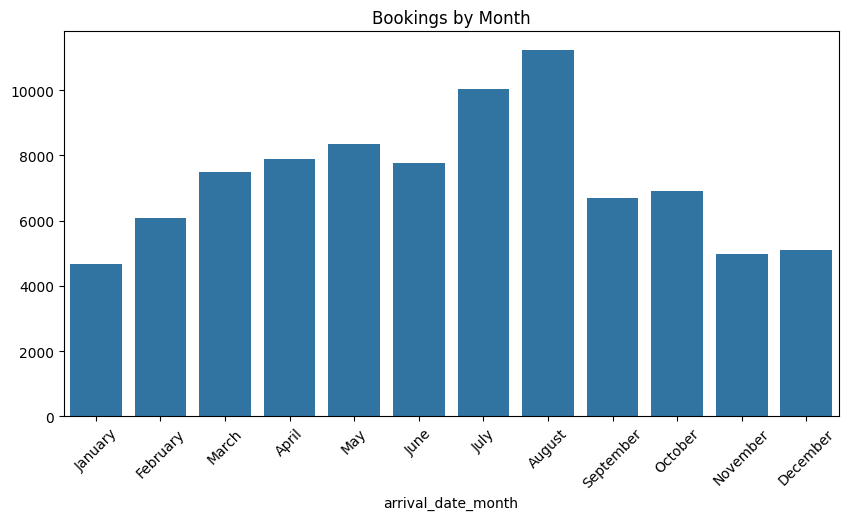

In [40]:
month_counts = df["arrival_date_month"].value_counts().reindex(months)
print(month_counts)
print("Highest:", month_counts.idxmax())

plt.figure(figsize=(10,5))
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.xticks(rotation=45)
plt.title("Bookings by Month")
plt.show()

August is the busiest month with 11,242 bookings, so demand peaks in summer.

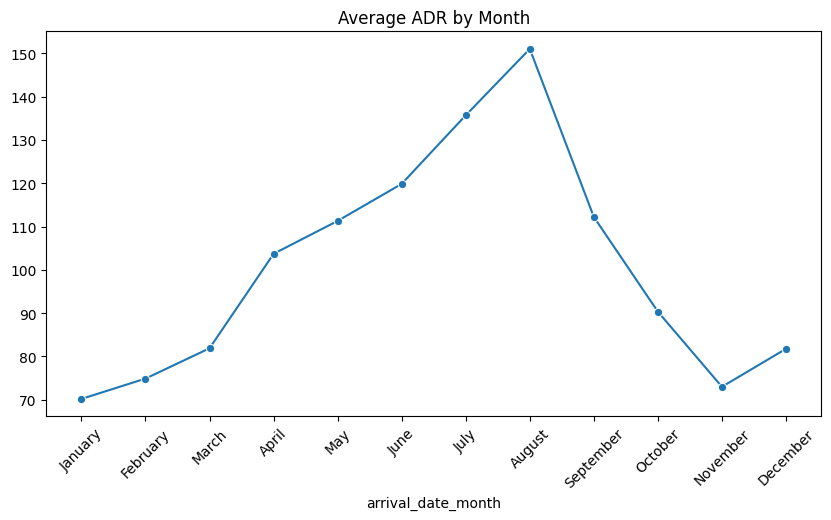

In [41]:
adr_month = df.groupby("arrival_date_month")["adr"].mean().reindex(months)

plt.figure(figsize=(10,5))
sns.lineplot(x=adr_month.index, y=adr_month.values, marker="o")
plt.xticks(rotation=45)
plt.title("Average ADR by Month")
plt.show()

ADR peaks in August at about 151 and is lowest in January at about 70, so pricing is strongly seasonal.

**# 5. Segmentation Analysis**

market_segment
Undefined        100.0
Online TA         35.4
Groups            27.1
Aviation          19.9
Offline TA/TO     14.8
Direct            14.7
Complementary     12.3
Corporate         12.1
Name: is_canceled, dtype: float64


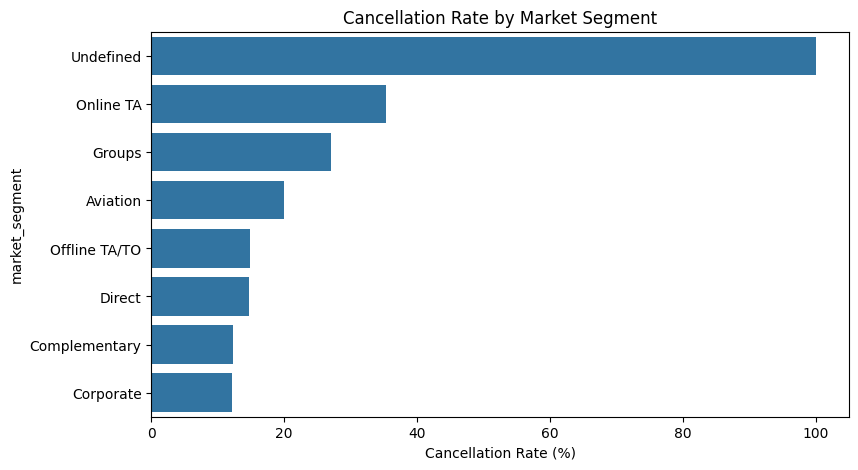

In [42]:
seg = df.groupby("market_segment")["is_canceled"].mean().sort_values(ascending=False) * 100
print(seg.round(1))

plt.figure(figsize=(9,5))
sns.barplot(x=seg.values, y=seg.index)
plt.xlabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Market Segment")
plt.show()

Online TA has the highest cancellation rate (about 35%), while Corporate and Direct are the lowest (about 12 to 15%).

In [43]:
ch = df.groupby("distribution_channel")["adr"].mean().sort_values(ascending=False)
print(ch.round(1))

distribution_channel
GDS          120.3
Direct       109.4
TA/TO        108.7
Corporate     68.8
Undefined     46.2
Name: adr, dtype: float64


GDS has the highest average ADR (about 120)

In [44]:
df["guest_type"] = np.where(df["country"] == "PRT", "Domestic", "International")

print(df["guest_type"].value_counts())
print(df.groupby("guest_type")["is_canceled"].mean().mul(100).round(1))
print(df["country"].value_counts().head(5))

guest_type
International    59874
Domestic         27355
Name: count, dtype: int64
guest_type
Domestic         35.8
International    23.8
Name: is_canceled, dtype: float64
country
PRT    27355
GBR    10423
FRA     8823
ESP     7244
DEU     5385
Name: count, dtype: int64


The hotels are in Portugal, so I treated PRT as domestic and all other countries as international.
International guests make up most bookings (59,874 vs 27,355). Domestic (PRT) guests cancel more (about 36% vs 24%). Top countries: PRT, GBR, FRA, ESP, DEU.

**# 6. Booking and Cancellation Analysis**

Q1. What is the average lead time for bookings that are cancelled versus those that are not cancelled?

is_canceled
0     70.2
1    105.7
Name: lead_time, dtype: float64


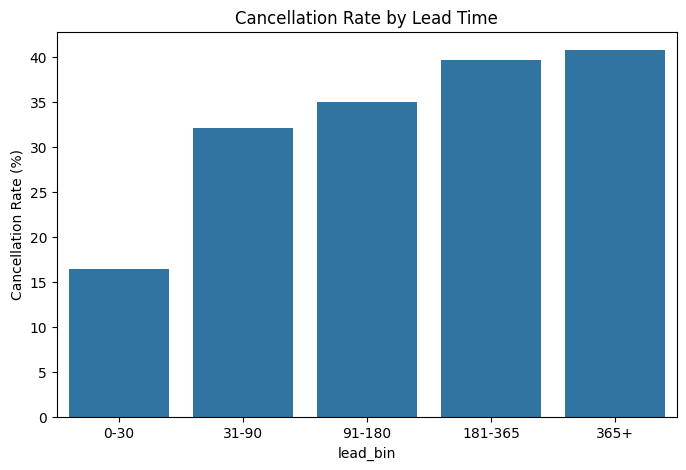

In [45]:
print(df.groupby("is_canceled")["lead_time"].mean().round(1))

df["lead_bin"] = pd.cut(df["lead_time"], [-1,30,90,180,365,800],
                        labels=["0-30","31-90","91-180","181-365","365+"])
lead_cancel = df.groupby("lead_bin", observed=True)["is_canceled"].mean() * 100

plt.figure(figsize=(8,5))
sns.barplot(x=lead_cancel.index, y=lead_cancel.values)
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Lead Time")
plt.show()

Cancelled bookings have a longer average lead time (about 106 days vs 70). The cancellation rate rises from about 16% for 0-30 days to about 41% for bookings made over a year ahead.

43441
0.7


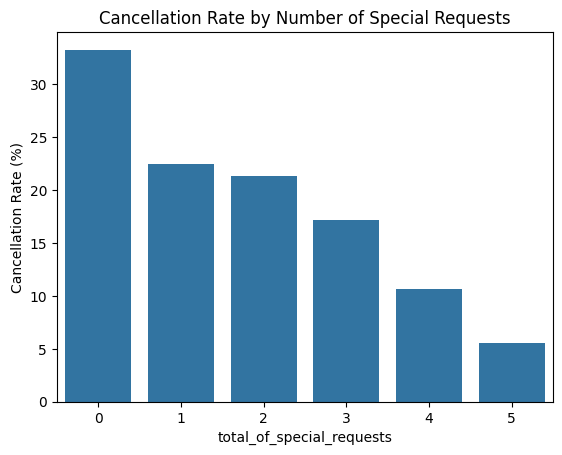

In [46]:
print((df["total_of_special_requests"] > 0).sum())
print(df["total_of_special_requests"].mean().round(2))

req_cancel = df.groupby("total_of_special_requests")["is_canceled"].mean() * 100
sns.barplot(x=req_cancel.index, y=req_cancel.values)
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Number of Special Requests")
plt.show()


Guests with no special requests cancel about 33% of the time. This drops steadily to about 6% for guests with 5 requests, which suggests more engaged guests are less likely to cancel.

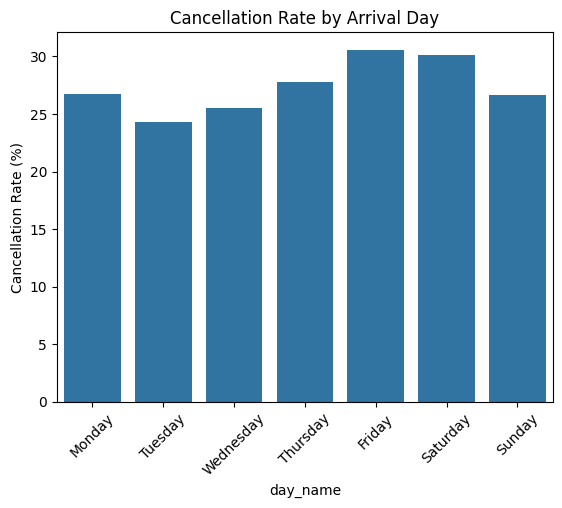

In [47]:
df["day_name"] = df["arrival_date"].dt.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
day_cancel = df.groupby("day_name")["is_canceled"].mean().reindex(order) * 100

sns.barplot(x=day_cancel.index, y=day_cancel.values)
plt.xticks(rotation=45)
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Arrival Day")
plt.show()

Cancellations are highest for Friday and Saturday arrivals (about 30%) and lowest for Tuesday (about 24%).

In [48]:
dep = df.groupby("deposit_type")["is_canceled"].mean() * 100
print(dep.round(1))

deposit_type
No Deposit    26.7
Non Refund    94.7
Refundable    24.3
Name: is_canceled, dtype: float64



Non-refundable bookings show about 95% cancellations. This is unusual and may need checking, because guests normally don't cancel non-refundable bookings.


**# 7. Objective Questions**

Q3. What is the distribution of ADR (Average Daily Rate) across different customer types?

In [49]:
print(df.groupby("customer_type")["adr"].describe().round(1))

                   count   mean   std  min   25%    50%    75%     max
customer_type                                                         
Contract          3135.0   92.9  35.0  0.0  68.0   91.0  113.7   250.0
Group              541.0   84.8  51.2  0.0  51.0   75.0  111.6   318.0
Transient        71862.0  110.3  56.5  0.0  75.0  102.3  139.5  5400.0
Transient-Party  11691.0   87.9  43.6  0.0  62.0   81.6  109.0   451.5


Transient customers pay the highest average ADR (about 110). Contract is about 93, Transient-Party about 88 and Group about 85

Q7. What is the correlation between lead time and the length of stay?

In [50]:
df["total_stay"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
print(df["lead_time"].corr(df["total_stay"]).round(3))

0.321



The correlation is about 0.32, a weak to moderate positive relationship. Guests who book earlier tend to stay slightly longer.

Q4. How many bookings had special requests, and what is the average number of special requests per booking?

In [51]:
print((df["total_of_special_requests"] > 0).sum())
print(df["total_of_special_requests"].mean().round(2))

43441
0.7


43,441 bookings had at least one special request, and the average is 0.70 requests per booking.

Q8. How many bookings include children and/or babies?

In [52]:
print("With children:", (df["children"] > 0).sum())
print("With babies:", (df["babies"] > 0).sum())
print("With children or babies:", ((df["children"] > 0) | (df["babies"] > 0)).sum())

With children: 8364
With babies: 914
With children or babies: 9103


8,364 bookings include children, 914 include babies, and 9,103 include children or babies (some include both).

Q9. What is the average lead time for repeated guests compared to new guests?

In [53]:
print(df.groupby("is_repeated_guest")["lead_time"].mean().round(1))

is_repeated_guest
0    82.5
1    17.3
Name: lead_time, dtype: float64


New guests book about 82 days ahead on average, while repeated guests book only about 17 days ahead.

Q10. What is the most common combination of reserved room type and assigned room type?

In [54]:
combo = df.groupby(["reserved_room_type", "assigned_room_type"]).size().sort_values(ascending=False)
print(combo.head(5))
print("Mismatch rate:", (df["reserved_room_type"] != df["assigned_room_type"]).mean().round(3))

reserved_room_type  assigned_room_type
A                   A                     45850
D                   D                     15979
A                   D                      6402
E                   E                      5458
F                   F                      2636
dtype: int64
Mismatch rate: 0.149


The most common combination is room A reserved and room A assigned (45,850 bookings). About 15% of bookings get a different room than reserved.

**# Subjective Questions**

**Q1. How does the lead time affect the likelihood of booking cancellations?**
Longer lead times mean higher cancellation risk. The rate rises from about 16% for bookings made 0-30 days ahead to about 41% for bookings made over 365 days ahead.

**Q2. What impact do special requests have on booking cancellations?**
Guests with more special requests cancel much less. The cancellation rate is about 33% with no requests and about 6% with five requests.

**Q3. What trends can be observed in the booking behavior of international guests compared to domestic guests?**
International guests make up most bookings (59,874 vs 27,355 domestic). They also cancel less (about 24%) than domestic Portuguese guests (about 36%).

**Q4. What is the impact of the day of the week on booking cancellations?**
Friday and Saturday arrivals have the highest cancellation rates (about 30%). Tuesday arrivals have the lowest (about 24%).

**Q5. What are the most common countries for international guests, and how do their booking patterns compare to domestic guests?**
The top countries are Portugal (PRT), Great Britain (GBR), France (FRA), Spain (ESP) and Germany (DEU). Among international guests, GBR, FRA, ESP and DEU lead. Compared with domestic guests, international guests book more often and cancel less.

**# Actionable Insights**

1. Charge a deposit or tighten the policy for bookings made more than 6 months ahead, since their cancellation rate is about 40%.
2. Review the Online TA channel, which has the highest cancellation rate (about 35%), and consider stricter cancellation terms there.
3. Encourage guests to add special requests at booking, because these guests are far less likely to cancel.
4. Use seasonal pricing: raise rates in July-August (ADR about 136-151) and offer promotions in January-March (ADR about 70-82).
5. Overbook slightly on Friday and Saturday arrivals and for domestic guests, where cancellations are higher.
6. Reduce room mismatches (about 15% of bookings get a different room than reserved) to improve guest satisfaction.
7. Reward repeated guests with loyalty perks, since they book late and are a reliable segment.